## Model Comparison Using Algorithm B1
# Plot AULD algorithm<br>
Model Comparison Using Algorithm B1
To assess whether differences in cross-validation performance between competing GEV formulations are statistically significant, we apply the randomization test of Auld et al. (2023, Algorithm B1). For each pair of models, observation-level score differences are computed from the five-fold cross-validation results. Under the null hypothesis that the two models are equally skillful, the score differences are exchangeable and their signs may be randomly permuted. A null distribution of mean score differences is generated using 10^5 random sign permutations, and a one-sided p-value is estimated as the proportion of randomized statistics greater than or equal to the observed mean score difference. Small p-values indicate statistical support for the model with the lower average score.

In [44]:
import numpy as np
import xarray as xr
from pathlib import Path


In [45]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy


In [46]:
import warnings
warnings.filterwarnings('ignore')

In [47]:

# ============================================================
# USER SETTINGS
# ============================================================

file_model0 = "/Volumes/Data/CMIP6_Large_Ensembles/GEV/TXx/NClimGrid_CONUS_TXx1_glostLocSca_extremes_gev_1952_2025.nc"
file_model1 = "/Volumes/Data/CMIP6_Large_Ensembles/GEV/TXx/NClimGrid_CONUS_TXx1_glostprLocSca_extremes_gev_1952_2025.nc"

metrics = [ "CRPS_cv","DawSeb_cv","SE_cv"]

# ============================================================
# Extract Model Names
# ============================================================
def extract_model_name(filename):
    stem = Path(filename).stem
    parts = stem.split("_")
    #                    ^
    return parts[3]

model0_name = extract_model_name(file_model0)
model1_name = extract_model_name(file_model1)
file_B1 = f"/Users/gahe5417/data/TXx/AlgorithmB1_{model0_name}_vs_{model1_name}.nc"

# ============================================================
# READ INPUT FILES
# ============================================================
ds0 = xr.open_dataset(file_model0)
ds1 = xr.open_dataset(file_model1)

nlat = len(ds0.lat)
nlon = len(ds0.lon)

for metric in metrics:
    ds0[metric] = ds0[metric].transpose("time", "lat", "lon").load()
    ds1[metric] = ds1[metric].transpose("time", "lat", "lon").load()


ds0.close()
ds1.close()

ds_pval = xr.open_dataset(file_B1)

In [48]:
state_borders =\
cartopy.feature.NaturalEarthFeature(category='cultural',\
        name='admin_1_states_provinces_lakes', scale='50m', facecolor='none')
# 1. Define the 50m rivers feature
rivers = cartopy.feature.NaturalEarthFeature(
    category='physical',
    name='rivers_lake_centerlines',
    scale='50m',
    facecolor='none',
    edgecolor='blue'  # Or use 'navy', 'royalblue', etc.
)

In [49]:
latN = 50
latS = 25
lonW = -119.5
lonE = -74

cLat = (latN + latS)/2
cLon = (lonW + lonE )/2

In [50]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()
cmap = mcolors.ListedColormap([ "#d73027", "#d9d9d9",    "#4575b4"])
norm = mcolors.BoundaryNorm([-1.5, -0.5, 0.5, 1.5],cmap.N)

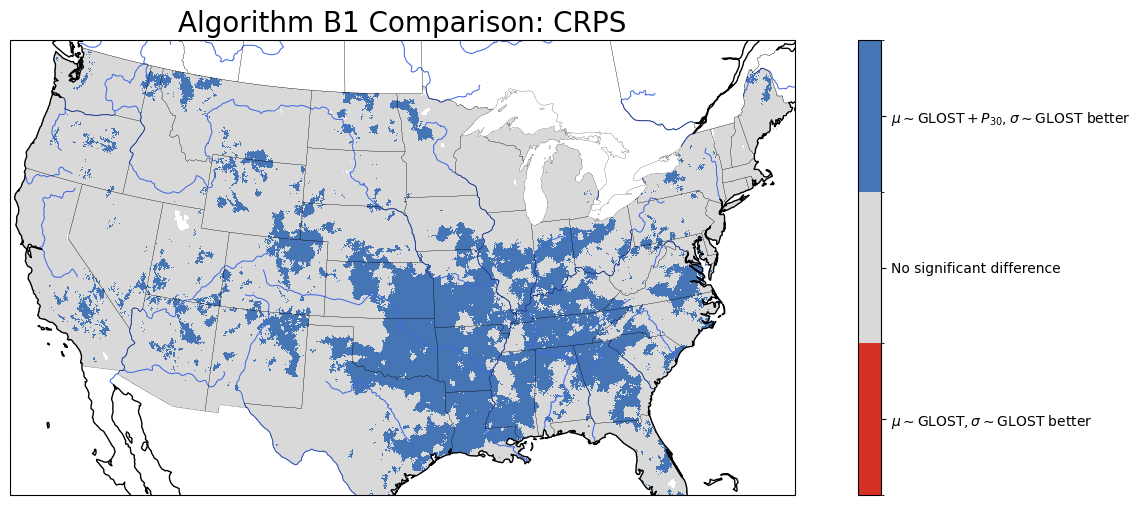

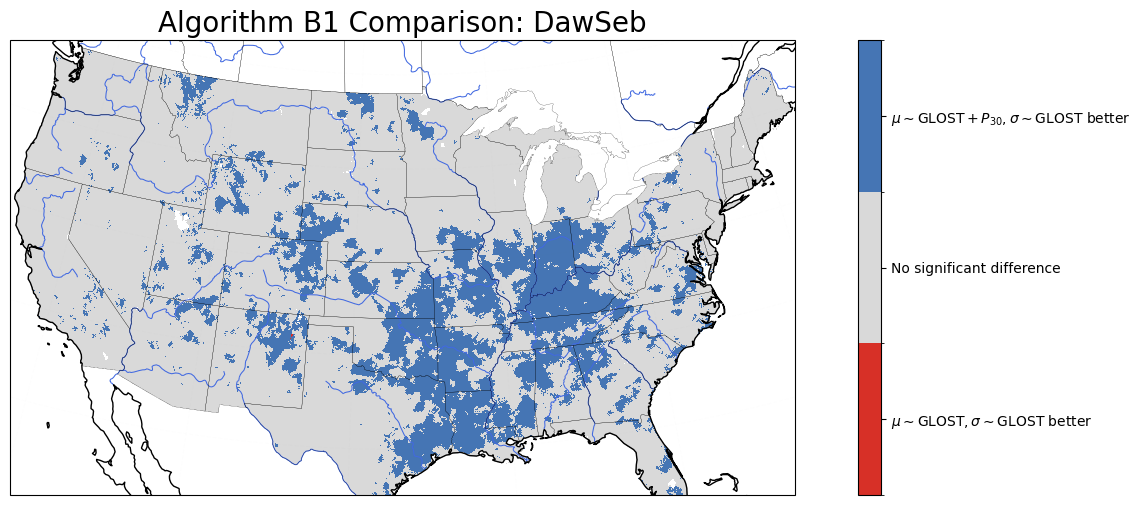

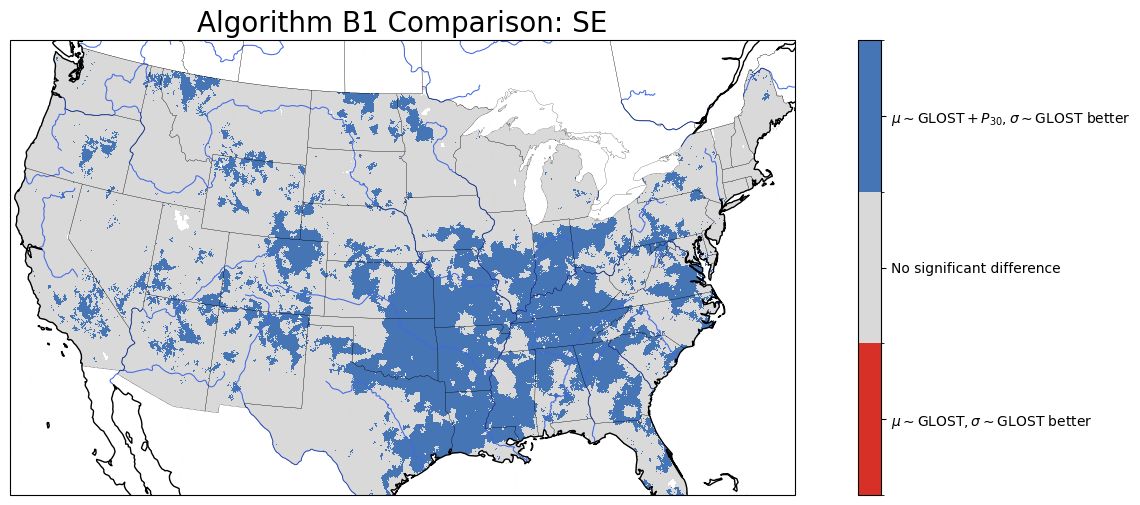

In [51]:
alpha = 0.05
for metric in metrics:
    metric_name = metric.replace("_cv", "")
    # Mean score difference
    # Positive means model1 has lower score (better)
    mean_diff = ( ds0[metric].mean("time") - ds1[metric].mean("time"))
    # Algorithm B1 p-values
    pval = ds_pval[f"{metric_name}_B1_pvalue"]
    comparison = xr.full_like(mean_diff, np.nan)
    # model1 significantly better
    comparison = xr.where((pval <= alpha) & (mean_diff > 0),1,comparison)
    # model0 significantly better
    comparison = xr.where((pval <= alpha) & (mean_diff < 0),-1,comparison)
    # no significant difference
    comparison = xr.where(pval > alpha,0,comparison)
    comparison.name = f"{metric_name}_better_model"
    
    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,7),subplot_kw={'projection':proj})
    plt.subplots_adjust(bottom=0.25,left=0.05, right=0.95,top=0.9,hspace=0.1,wspace=0.05)
    comparison.plot(ax=ax,cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
    ####
    grd = ax.gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
    grd.top_labels = False   # Disable top labels
    grd.right_labels = False # Disable right labels. 
    ax.set_extent((lonW,lonE,latS,latN))
    ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
    ax.add_feature(rivers, edgecolor='royalblue', linewidth=0.75)
    ax.coastlines()
    #
    cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=cmap,norm=norm,),ax=ax,ticks=[-1, 0, 1])
    cbar.ax.set_yticklabels(["$\mu \sim \mathrm{GLOST}, \sigma \sim \mathrm{GLOST}$ better", "No significant difference","$\mu \sim \mathrm{GLOST} + P_{30}, \sigma \sim \mathrm{GLOST}$ better",])
    cbar.set_label('')
    ax.set_title(f"Algorithm B1 Comparison: {metric_name}",fontsize=20)
    plt.show()

*Spatial comparison of predictive performance between two nonstationary GEV model formulations: a GLOST-only model ($\mu \sim \mathrm{GLOST}, \sigma \sim \mathrm{GLOST}$) and a model that additionally includes antecedent 30-day precipitation in the location parameter ($\mu \sim \mathrm{GLOST} + P_{30}, \sigma \sim \mathrm{GLOST}$). Panels show results for the continuous ranked probability score (CRPS), Dawid-Sebastiani score and squared error (SE). Blue shading indicates locations where the GLOST+$P_{30}$​ model exhibits significantly superior predictive performance relative to the GLOST-only model, whereas red shading indicates locations where the GLOST-only model performs significantly better. Gray shading denotes locations where no statistically significant difference in predictive performance is detected. Statistical significance was assessed using the Algorithm B1 randomization test of Auld et al. (2023) at the $\alpha = 0.05$ significance level.*